Using Colab cache for faster access to the 'nifty-50-100-500-historical-data-19952026' dataset.
Dataset downloaded to: /kaggle/input/nifty-50-100-500-historical-data-19952026
CSV files found:
NIFTY50_1995_to_Feb_2026.csv
NIFTY500_2005_to_Feb_2026.csv
NIFTY100_2005_to_Feb_2026.csv

Using file: NIFTY50_1995_to_Feb_2026.csv

Columns:
['Date', 'Close', 'High', 'Low', 'Open', 'Volume', 'Ticker', 'Daily_Return_%', 'MA_50', 'MA_200']

First 5 rows:
         Date             Close              High               Low  \
0         NaN             ^NSEI             ^NSEI             ^NSEI   
1  2007-09-17  4494.64990234375   4549.0498046875  4482.85009765625   
2  2007-09-18   4546.2001953125   4551.7998046875   4481.5498046875   
3  2007-09-19  4732.35009765625            4739.0           4550.25   
4  2007-09-20   4747.5498046875  4760.85009765625  4721.14990234375   

               Open Volume Ticker  Daily_Return_%  MA_50  MA_200  
0             ^NSEI  ^NSEI    NaN             NaN    NaN    

/tmp/ipykernel_2828/2341091603.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Date"] = pd.to_datetime(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 69ms/step - loss: 0.0042 - val_loss: 0.0039
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - loss: 8.2091e-04 - val_loss: 8.5670e-04
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - loss: 7.2910e-04 - val_loss: 0.0028
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - loss: 6.8121e-04 - val_loss: 0.0013
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - loss: 6.1023e-04 - val_loss: 0.0022
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - loss: 5.5675e-04 - val_loss: 2.7851e-04
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - loss: 5.7170e-04 - val_loss: 0.0012
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - loss: 5.1727e-04 - val_loss: 3.1163e-04
Epoch 9/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - loss: 4.6481e-04 - val_loss: 2.3502e-04
Epoch 10/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - loss: 4.7363e-04 - val_loss: 2.6284e-04
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step

RMSE: 385.9260089299691


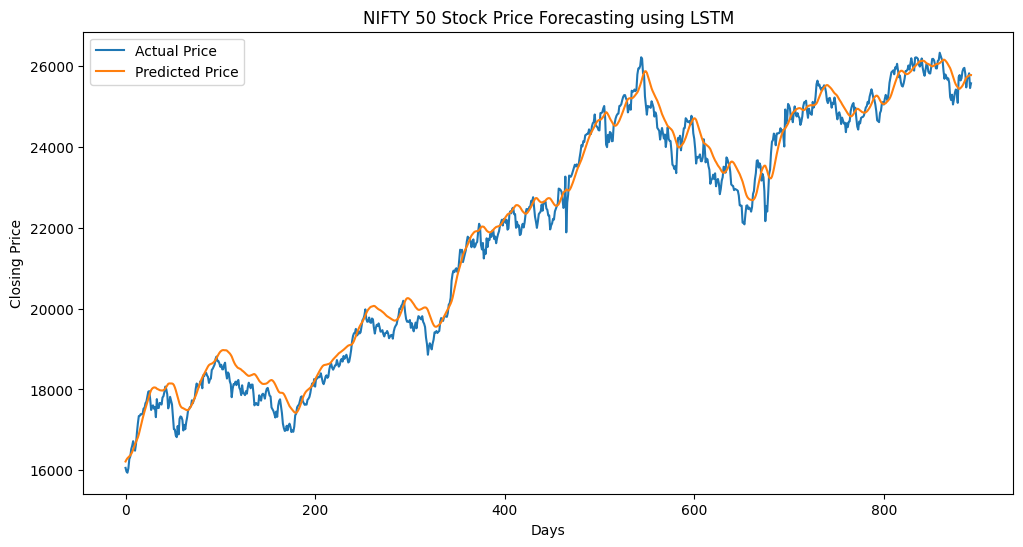

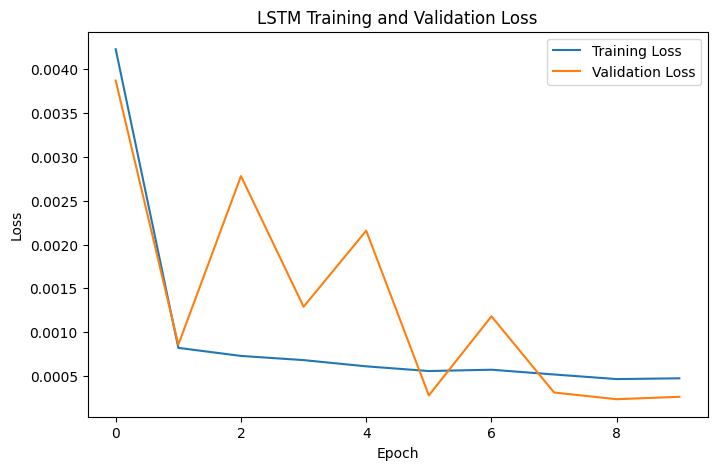

In [3]:
!pip install kagglehub tensorflow scikit-learn pandas matplotlib -q

import kagglehub
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Download Kaggle dataset
path = kagglehub.dataset_download(
    "vaibhavshinde97/nifty-50-100-500-historical-data-19952026"
)

print("Dataset downloaded to:", path)

# Find all CSV files
csv_files = glob.glob(path + "/**/*.csv", recursive=True)

print("CSV files found:")
for file in csv_files:
    print(os.path.basename(file))

# Find a CSV containing a Close column
data = None

for file in csv_files:
    try:
        temp = pd.read_csv(file)

        # Remove spaces from column names
        temp.columns = temp.columns.str.strip()

        if "Close" in temp.columns:
            data = temp
            print("\nUsing file:", os.path.basename(file))
            break

    except Exception:
        pass

if data is None:
    raise ValueError("No CSV file containing a Close column was found.")

# Display columns
print("\nColumns:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
print(data.head())

# Convert Close column to numeric
data["Close"] = pd.to_numeric(
    data["Close"],
    errors="coerce"
)

# Remove invalid/missing prices
data = data.dropna(subset=["Close"])

# Sort by date if Date exists
if "Date" in data.columns:
    data["Date"] = pd.to_datetime(
        data["Date"],
        errors="coerce"
    )
    data = data.dropna(subset=["Date"])
    data = data.sort_values("Date")

# Get closing prices
prices = data["Close"].values.reshape(-1, 1)

print("\nNumber of price records:", len(prices))

# Normalize data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(prices)

# Create sequences
time_step = 60

X = []
y = []

for i in range(time_step, len(scaled_data)):
    X.append(scaled_data[i-time_step:i, 0])
    y.append(scaled_data[i, 0])

X = np.array(X)
y = np.array(y)

# Reshape for LSTM
X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

# Train-test split
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Build LSTM model
model = Sequential()

model.add(
    LSTM(
        50,
        return_sequences=True,
        input_shape=(time_step, 1)
    )
)

model.add(Dropout(0.2))

model.add(LSTM(50))

model.add(Dropout(0.2))

model.add(Dense(1))

# Compile
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Train
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, y_test)
)

# Predict
predicted = model.predict(X_test)

# Convert to original price
predicted = scaler.inverse_transform(predicted)

actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

# RMSE
rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("\nRMSE:", rmse)

# Plot actual vs predicted
plt.figure(figsize=(12, 6))

plt.plot(
    actual,
    label="Actual Price"
)

plt.plot(
    predicted,
    label="Predicted Price"
)

plt.title("NIFTY 50 Stock Price Forecasting using LSTM")
plt.xlabel("Days")
plt.ylabel("Closing Price")
plt.legend()
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()